In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Setup Device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on: {device}")

# 2. Hyperparameters
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 5

# 3. Download and Prepare the MNIST Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

# 4. Define the Neural Network Model
class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

model = SimpleNN().to(device)

# 5. Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 6. Train the Model
print("\nTraining started...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()           # Reset gradients
        outputs = model(images)         # Forward pass
        loss = criterion(outputs, labels) # Calculate error
        loss.backward()                 # Backpropagation
        optimizer.step()                # Update model weights

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {total_loss / len(train_loader):.4f}")

# 7. Test Accuracy
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"\nAccuracy on 10,000 test images: {100 * correct / total:.2f}%")




Running on: cpu


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 161kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.2MB/s]



Training started...
Epoch 1/5 | Loss: 0.2765
Epoch 2/5 | Loss: 0.1120
Epoch 3/5 | Loss: 0.0793
Epoch 4/5 | Loss: 0.0604
Epoch 5/5 | Loss: 0.0469

Accuracy on 10,000 test images: 97.85%


In [3]:
# 8. Test a Single Sample Prediction
sample_image, actual_label = test_data[7]
with torch.no_grad():
    sample_image = sample_image.unsqueeze(0).to(device)
    prediction = model(sample_image).argmax(dim=1).item()

print(f"Sample Check -> Actual Digit: {actual_label} | Predicted Digit: {prediction}")

Sample Check -> Actual Digit: 9 | Predicted Digit: 9


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving Image-9-from-MNIST-1280-x-640-V1.0.png to Image-9-from-MNIST-1280-x-640-V1.0 (3).png


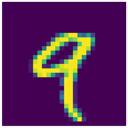

9


In [9]:
from google.colab import files
from google.colab import drive
from torchvision import datasets, transforms
drive.mount('/content/drive')
from IPython.display import display

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5))
])

upload = files.upload()
input_image = next(iter(upload))
from PIL import Image

display(Image.open(input_image).resize((128, 128)))

import torch

#Image Prediction
model.eval()
with torch.inference_mode():
  img = Image.open(input_image).convert("L")
  img_t = transform(img).unsqueeze(0).to(device)
  pred = model(img_t).argmax(dim=1).item()
print(pred)
